# Metamodel validation (propagation holdout)

Three steps:

1. **Fit** — `mm.fit(goal)` or `mm.fit_all()`
2. **Validate** — `val.sweep(goal)` for metrics; `val.validate(goal, n=…)` for plotting
3. **Plot** — `result.plot('10m')`, `result.plot_all()`, …

Validation loads saved models only (no refitting). Holdout metrics and plots
include **`hs`, `tp`, `dir`, `spr`** (`spr` via PCA; `tp` raw). Use
`mm.report_training_data(goal, n=450)` or `mm.load_fit_summary(goal, 450)` after
fit to inspect site filter and PCA site retention.

In [1]:
import matplotlib.pyplot as plt
from utils.config import METAMODEL, load_goals, mda_max_points
from utils.evaluation import validation as val
from utils.model import metamodel as mm

In [2]:
goals = list(load_goals().keys())
candidates = METAMODEL["mda_candidates"]
metrics = METAMODEL["validation"]["metrics_variables"]
site_filter = METAMODEL["site_filter"]

print(f"goals      : {goals}")
print(f"candidates : {candidates}")
print(f"metrics    : {metrics}")
print(f"MDA max    : {mda_max_points()} (test cases = 500 - max)")
for key, threshold in site_filter.items():
    if key.endswith("_max"):
        var = key[:-4]
        print(f"{var} filter : > {threshold} removed before PCA (site_filter)")
    elif key.endswith("_min"):
        var = key[:-4]
        print(f"{var} filter : < {threshold} removed before PCA (site_filter)")
print("PCA NaN    : dry-site handling in metamodel.pca_preprocessing (see README)")

goals      : ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26']
candidates : [50, 100, 150, 250, 450]
metrics    : ['hs', 'tp', 'dir', 'spr']
MDA max    : 450 (test cases = 500 - max)
hs filter : > 10.0 removed before PCA (site_filter)
tp filter : < 0.5 removed before PCA (site_filter)
PCA NaN    : dry-site handling in metamodel.pca_preprocessing (see README)


## 1 · Fit

In [ ]:
# All goals:
# mm.fit_all(gp_epochs=1500)

## 2 · Validate

In [ ]:
# Metrics for every MDA size → outputs/goal_01/validation_metrics.csv
metrics = val.sweep(4)
metrics.head()

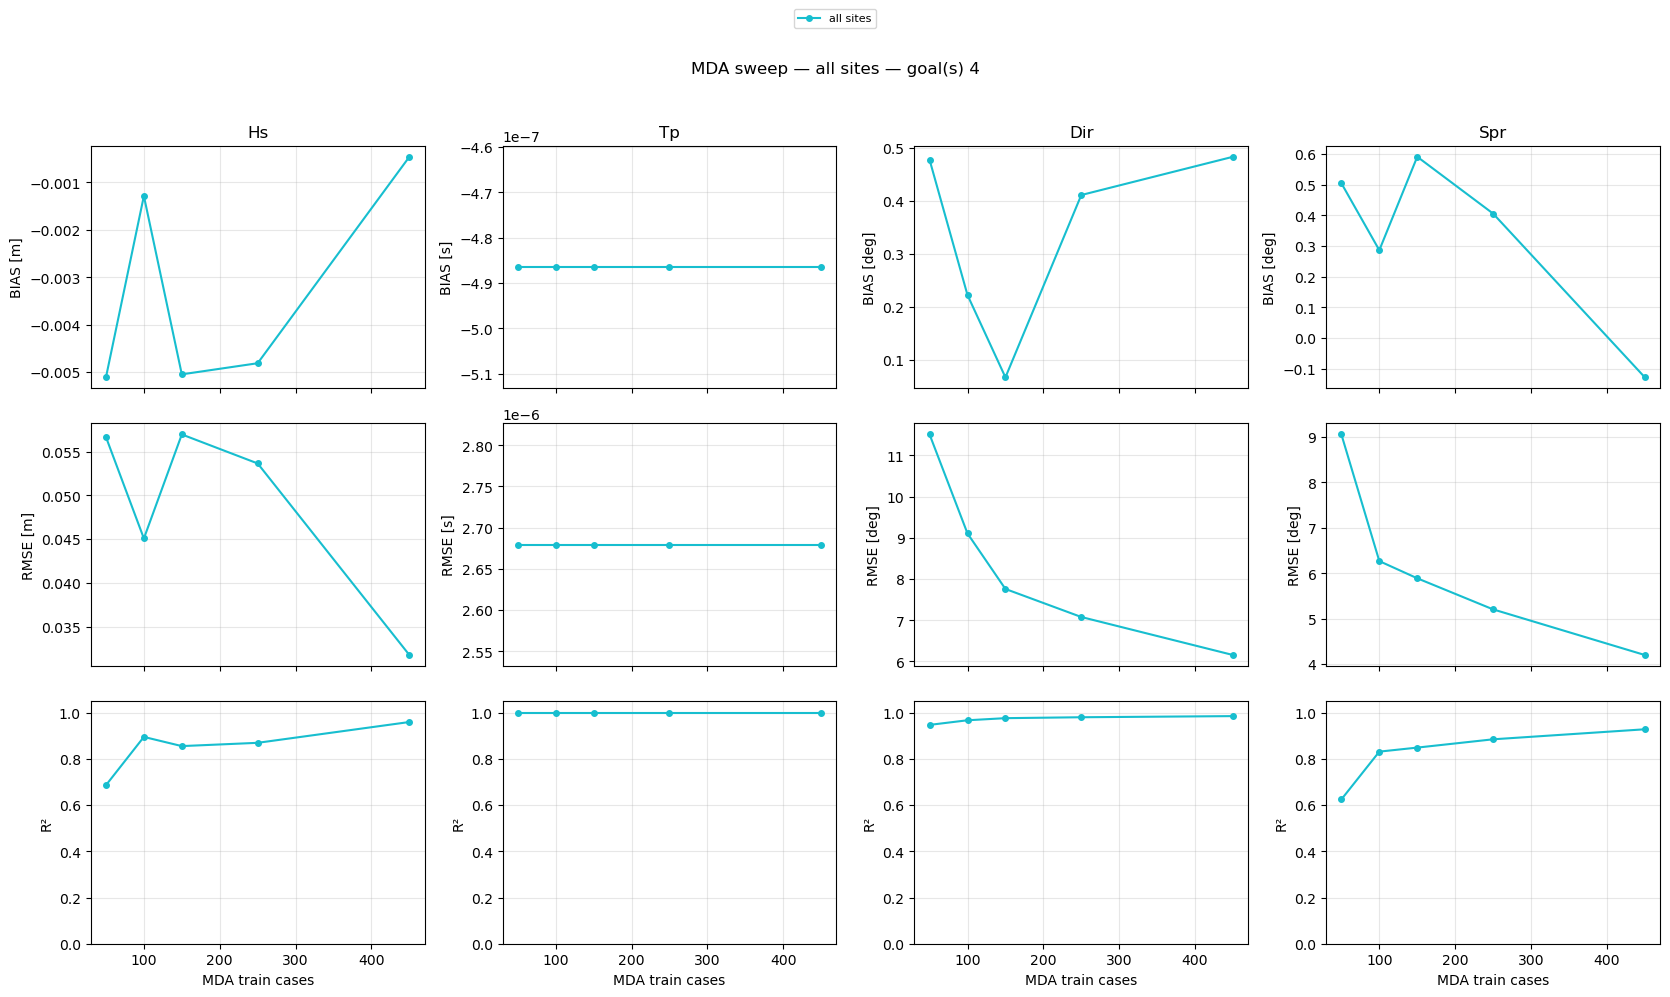

In [8]:
val.plot_sweep(metrics, by="bulk")
plt.show()

## 3 · Plot

In [ ]:
n = 450  # MDA size to plot
result = val.validate(4, n)

# Available groups: isobath depths, mesh labels, buoy ids
[g[0] for g in val.metric_groups(result.estimate)]

In [12]:
# Map only, or scatters only
# result.plot_map("10m")
# result.plot_scatter("10m", variables=["hs"])

# All groups (optionally filter variables or groups)
for fig in result.plot_all(groups="waves", reference_label="buoy_ByronBay_Buoy"):
    plt.show()

## All goals

In [ ]:
all_metrics = val.sweep_all()
all_metrics

In [3]:
# Best MDA size per goal (10m isobath, Hs)
hs_10m = all_metrics.query("site_label == '10m' and variable == 'hs'")
best = hs_10m.loc[hs_10m.groupby("goal")["rmse"].idxmin()]
best[["goal", "mda_candidate", "site_label", "rmse", "r2", "n"]]

,goal,mda_candidate,site_label,rmse,r2,n
628,1,450,10m,0.014717,0.983550,45864
7648,10,450,10m,0.028140,0.959049,45864
8428,11,450,10m,0.028299,0.959666,45864
9208,12,450,10m,0.019100,0.982501,45864
9988,13,450,10m,0.033435,0.936345,45864
10768,14,450,10m,0.029761,0.963252,45864
11548,15,450,10m,0.026902,0.972954,45864
12328,16,450,10m,0.032473,0.954190,45864
13108,17,450,10m,0.033241,0.969971,45864
13888,18,450,10m,0.035463,0.971855,45864
